<a href="https://colab.research.google.com/github/Camilososa22/AirMed/blob/main/02_preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AirMed: preparación de datos para Deep Learning

## 1. Objetivo

Preparar los registros históricos de PM2.5 de la estación MED-PBLQ para entrenar modelos de redes neuronales recurrentes.

## 2. Actividades

- Cargar y ordenar las observaciones cronológicamente.
- Verificar la continuidad de la serie temporal.
- Identificar y tratar los valores faltantes.
- Separar los datos en entrenamiento, validación y prueba.
- Preparar la información para construir secuencias temporales.

## 3. Configuración inicial

- Variable objetivo: PM2.5.
- Frecuencia: horaria.
- Ventana histórica: 168 horas.
- Horizonte de predicción: 24 horas.
- División temporal: 70 % entrenamiento, 15 % validación y 15 % prueba.
- Arquitectura inicial: LSTM.

In [3]:
# ============================================================
# AIRMED
# CONEXIÓN CON GOOGLE DRIVE
# ============================================================

from google.colab import drive

# Conectar Google Drive con el entorno de Colab
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# ============================================================
# AIRMED
# PASO 5.4: CARGA Y VERIFICACIÓN DE LOS DATOS
# ============================================================

import pandas as pd
import numpy as np

# Ruta del dataset almacenado en Google Drive
ruta_dataset = (
    "/content/drive/MyDrive/AirMed/data/raw/"
    "airmed_medpblq_2026_01_08.csv"
)

# Cargar los datos
df_model = pd.read_csv(
    ruta_dataset,
    parse_dates=["timestamp"]
)

# Ordenar cronológicamente
df_model = (
    df_model
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Conservar los registros necesarios para el primer modelo
df_model = df_model[
    ["timestamp", "pm25_ug_m3"]
].copy()

# Registrar cuáles mediciones estaban originalmente faltantes
df_model["pm25_was_missing"] = (
    df_model["pm25_ug_m3"].isna()
)

# Mostrar información general
print("AIRMED - PREPARACIÓN DEL CONJUNTO DE DATOS")
print("-" * 50)

print(f"Total de registros: {len(df_model)}")
print(f"Primera medición: {df_model['timestamp'].min()}")
print(f"Última medición: {df_model['timestamp'].max()}")

print(
    "\nValores faltantes originales:",
    df_model["pm25_was_missing"].sum()
)

print(
    "Marcas de tiempo duplicadas:",
    df_model["timestamp"].duplicated().sum()
)

print("\nPrimeros registros:")
display(df_model.head())

AIRMED - PREPARACIÓN DEL CONJUNTO DE DATOS
--------------------------------------------------
Total de registros: 5832
Primera medición: 2026-01-01 00:00:00
Última medición: 2026-08-31 23:00:00

Valores faltantes originales: 68
Marcas de tiempo duplicadas: 0

Primeros registros:


,timestamp,pm25_ug_m3,pm25_was_missing
0,2026-01-01 00:00:00,191.0,False
1,2026-01-01 01:00:00,37.0,False
2,2026-01-01 02:00:00,39.0,False
3,2026-01-01 03:00:00,45.0,False
4,2026-01-01 04:00:00,25.0,False


In [5]:
# ============================================================
# AIRMED
# PASO 5.5: TRATAMIENTO INICIAL DE VALORES FALTANTES
# ============================================================

# Guardar el número original de valores faltantes
faltantes_originales = int(
    df_model["pm25_was_missing"].sum()
)

# Completar como máximo tres horas consecutivas
# utilizando el último valor disponible.
df_model["pm25_ug_m3"] = (
    df_model["pm25_ug_m3"]
    .ffill(limit=3)
)

# Comprobar los resultados
faltantes_restantes = int(
    df_model["pm25_ug_m3"].isna().sum()
)

print("RESULTADOS DEL PREPROCESAMIENTO")
print("-" * 45)

print(
    f"Valores faltantes originales: "
    f"{faltantes_originales}"
)

print(
    f"Valores completados: "
    f"{faltantes_originales - faltantes_restantes}"
)

print(
    f"Valores faltantes restantes: "
    f"{faltantes_restantes}"
)

# Mostrar algunos registros que originalmente estaban faltantes
print("\nEjemplos de valores completados:")

display(
    df_model.loc[
        df_model["pm25_was_missing"],
        ["timestamp", "pm25_ug_m3", "pm25_was_missing"]
    ].head(10)
)

RESULTADOS DEL PREPROCESAMIENTO
---------------------------------------------
Valores faltantes originales: 68
Valores completados: 68
Valores faltantes restantes: 0

Ejemplos de valores completados:


,timestamp,pm25_ug_m3,pm25_was_missing
209,2026-01-09 17:00:00,18.0,True
299,2026-01-13 11:00:00,18.0,True
485,2026-01-21 05:00:00,18.0,True
509,2026-01-22 05:00:00,11.0,True
539,2026-01-23 11:00:00,11.0,True
556,2026-01-24 04:00:00,16.0,True
636,2026-01-27 12:00:00,13.0,True
652,2026-01-28 04:00:00,16.0,True
680,2026-01-29 08:00:00,9.0,True
731,2026-01-31 11:00:00,14.0,True


In [6]:
# ============================================================
# AIRMED
# PASO 5.6: DIVISIÓN CRONOLÓGICA
# ============================================================

# Cantidad total de registros
n = len(df_model)

# Límites de los conjuntos
train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Crear los conjuntos manteniendo el orden temporal
train_df = df_model.iloc[:train_end].copy()

val_df = df_model.iloc[
    train_end:val_end
].copy()

test_df = df_model.iloc[
    val_end:
].copy()

# Resumir las divisiones
conjuntos = {
    "Entrenamiento": train_df,
    "Validación": val_df,
    "Prueba": test_df
}

print("DIVISIÓN CRONOLÓGICA DEL DATASET")
print("-" * 65)

for nombre, conjunto in conjuntos.items():

    print(f"\n{nombre}")
    print(f"Registros: {len(conjunto)}")
    print(f"Fecha inicial: {conjunto['timestamp'].min()}")
    print(f"Fecha final: {conjunto['timestamp'].max()}")

    print(
        "Mediciones originalmente faltantes:",
        int(conjunto["pm25_was_missing"].sum())
    )

print("\nComprobación de los tamaños:")
print(
    f"Total: {len(train_df) + len(val_df) + len(test_df)}"
)

DIVISIÓN CRONOLÓGICA DEL DATASET
-----------------------------------------------------------------

Entrenamiento
Registros: 4082
Fecha inicial: 2026-01-01 00:00:00
Fecha final: 2026-06-20 01:00:00
Mediciones originalmente faltantes: 43

Validación
Registros: 875
Fecha inicial: 2026-06-20 02:00:00
Fecha final: 2026-07-26 12:00:00
Mediciones originalmente faltantes: 15

Prueba
Registros: 875
Fecha inicial: 2026-07-26 13:00:00
Fecha final: 2026-08-31 23:00:00
Mediciones originalmente faltantes: 10

Comprobación de los tamaños:
Total: 5832


In [7]:
# ============================================================
# AIRMED
# PASO 5.7: NORMALIZACION DE LOS DATOS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import RobustScaler

# ------------------------------------------------------------
# 1. Configurar el escalador
# ------------------------------------------------------------

scaler = RobustScaler()

# Seleccionar únicamente las mediciones reales del entrenamiento.
# Los valores completados no participan en el ajuste del escalador.
pm25_entrenamiento_real = train_df.loc[
    ~train_df["pm25_was_missing"],
    ["pm25_ug_m3"]
]

# Ajustar el escalador solamente con datos de entrenamiento
scaler.fit(pm25_entrenamiento_real)

# ------------------------------------------------------------
# 2. Transformar la serie completa
# ------------------------------------------------------------

# El escalador ya está ajustado.
# Ahora aplicamos esa transformación a todos los registros.
pm25_scaled = scaler.transform(
    df_model[["pm25_ug_m3"]]
).astype(np.float32).reshape(-1)

# Identificar cuáles mediciones son observaciones reales.
# False significa que el valor fue completado durante
# el preprocesamiento.
observaciones_validas = (
    ~df_model["pm25_was_missing"].to_numpy()
)

# ------------------------------------------------------------
# 3. Mostrar resultados
# ------------------------------------------------------------

print("NORMALIZACION DE AIRMED")
print("-" * 45)

print(
    "Mediciones reales utilizadas para ajustar el escalador:",
    len(pm25_entrenamiento_real)
)

print(
    "Registros transformados:",
    len(pm25_scaled)
)

print(
    "Mediana utilizada por RobustScaler:",
    scaler.center_[0]
)

print(
    "Rango intercuartil utilizado:",
    scaler.scale_[0]
)

print("\nPrimeros valores originales:")
print(df_model["pm25_ug_m3"].head().to_list())

print("\nPrimeros valores transformados:")
print(pm25_scaled[:5])

print(
    "\nCantidad de mediciones originales faltantes:",
    (~observaciones_validas).sum()
)

NORMALIZACION DE AIRMED
---------------------------------------------
Mediciones reales utilizadas para ajustar el escalador: 4039
Registros transformados: 5832
Mediana utilizada por RobustScaler: 13.0
Rango intercuartil utilizado: 10.0

Primeros valores originales:
[191.0, 37.0, 39.0, 45.0, 25.0]

Primeros valores transformados:
[17.8  2.4  2.6  3.2  1.2]

Cantidad de mediciones originales faltantes: 68


In [8]:
# ============================================================
# AIRMED
# PASO 5.7.3: CONSTRUCCION DE SECUENCIAS TEMPORALES
# ============================================================

# ------------------------------------------------------------
# 1. Definir la configuracion temporal
# ------------------------------------------------------------

LONGITUD_ENTRADA = 168  # Ultimas 168 horas
HORIZONTE = 24          # Predecir las siguientes 24 horas

# Limites cronologicos de los conjuntos
n_entrenamiento = len(train_df)

n_validacion = (
    n_entrenamiento + len(val_df)
)

n_total = len(df_model)

print("CONFIGURACION DE LAS SECUENCIAS")
print("-" * 45)
print(f"Longitud de entrada: {LONGITUD_ENTRADA} horas")
print(f"Horizonte de prediccion: {HORIZONTE} horas")

# ------------------------------------------------------------
# 2. Funcion para construir las secuencias
# ------------------------------------------------------------

def crear_secuencias(
    indice_inicio,
    indice_fin,
    longitud_entrada,
    horizonte
):
    """
    Crea secuencias historicas y objetivos futuros.

    Parametros
    ----------
    indice_inicio : int
        Primer indice permitido para iniciar el objetivo.

    indice_fin : int
        Limite exclusivo del periodo analizado.

    longitud_entrada : int
        Numero de horas historicas utilizadas como entrada.

    horizonte : int
        Numero de horas futuras que se quieren predecir.

    Retorna
    -------
    X : array
        Forma (muestras, longitud_entrada, 1).

    Y : array
        Forma (muestras, horizonte).

    indices_objetivo : array
        Indices temporales correspondientes al inicio
        de cada horizonte de prediccion.
    """

    X = []
    Y = []
    indices_objetivo = []

    # Cada muestra utiliza las 168 horas anteriores
    # y las siguientes 24 horas como objetivo.
    ultimo_indice = indice_fin - horizonte

    for inicio_objetivo in range(
        max(indice_inicio, longitud_entrada),
        ultimo_indice + 1
    ):

        fin_objetivo = inicio_objetivo + horizonte

        # Identificar las 24 observaciones objetivo
        # de esta secuencia.
        mascara_objetivo = observaciones_validas[
            inicio_objetivo:fin_objetivo
        ]

        # No entrenar ni evaluar con objetivos que contengan
        # mediciones completadas artificialmente.
        if not mascara_objetivo.all():
            continue

        # Entrada: las 168 horas anteriores.
        X.append(
            pm25_scaled[
                inicio_objetivo - longitud_entrada:
                inicio_objetivo
            ].reshape(longitud_entrada, 1)
        )

        # Salida: las siguientes 24 horas.
        Y.append(
            pm25_scaled[
                inicio_objetivo:fin_objetivo
            ]
        )

        indices_objetivo.append(inicio_objetivo)

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(Y, dtype=np.float32),
        np.asarray(indices_objetivo, dtype=np.int64)
    )


# ------------------------------------------------------------
# 3. Crear los tres conjuntos
# ------------------------------------------------------------

# Entrenamiento: objetivos dentro del periodo de entrenamiento.
X_train, y_train, indices_train = crear_secuencias(
    indice_inicio=0,
    indice_fin=n_entrenamiento,
    longitud_entrada=LONGITUD_ENTRADA,
    horizonte=HORIZONTE
)

# Validacion: objetivos dentro del periodo de validacion.
# La entrada historica puede incluir datos anteriores
# al inicio de la validacion.
X_val, y_val, indices_val = crear_secuencias(
    indice_inicio=n_entrenamiento,
    indice_fin=n_validacion,
    longitud_entrada=LONGITUD_ENTRADA,
    horizonte=HORIZONTE
)

# Prueba: objetivos dentro del periodo de prueba.
X_test, y_test, indices_test = crear_secuencias(
    indice_inicio=n_validacion,
    indice_fin=n_total,
    longitud_entrada=LONGITUD_ENTRADA,
    horizonte=HORIZONTE
)


# ------------------------------------------------------------
# 4. Mostrar las dimensiones obtenidas
# ------------------------------------------------------------

print("\nDIMENSIONES DE LAS SECUENCIAS")
print("-" * 45)

print("\nEntrenamiento")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidacion")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nPrueba")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTotal de secuencias validas:")
print(
    len(X_train) + len(X_val) + len(X_test)
)

# ------------------------------------------------------------
# 5. Verificaciones
# ------------------------------------------------------------

assert X_train.ndim == 3
assert X_val.ndim == 3
assert X_test.ndim == 3

assert X_train.shape[1:] == (168, 1)
assert X_val.shape[1:] == (168, 1)
assert X_test.shape[1:] == (168, 1)

assert y_train.shape[1] == 24
assert y_val.shape[1] == 24
assert y_test.shape[1] == 24

print("\nVerificaciones completadas correctamente.")

CONFIGURACION DE LAS SECUENCIAS
---------------------------------------------
Longitud de entrada: 168 horas
Horizonte de prediccion: 24 horas

DIMENSIONES DE LAS SECUENCIAS
---------------------------------------------

Entrenamiento
X_train: (3104, 168, 1)
y_train: (3104, 24)

Validacion
X_val: (640, 168, 1)
y_val: (640, 24)

Prueba
X_test: (637, 168, 1)
y_test: (637, 24)

Total de secuencias validas:
4381

Verificaciones completadas correctamente.


In [9]:
# ============================================================
# AIRMED
# PASO 6.2: CONSTRUCCION DE LA RED NEURONAL LSTM
# ============================================================

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Fijar semillas para facilitar la reproducibilidad
tf.keras.utils.set_random_seed(42)

# ------------------------------------------------------------
# 1. Definir la arquitectura
# ------------------------------------------------------------

modelo_lstm = Sequential([
    # Entrada: 168 horas historicas y una variable
    Input(shape=(LONGITUD_ENTRADA, 1)),

    # Capa recurrente
    LSTM(
        units=64,
        return_sequences=False
    ),

    # Regularizacion para reducir el sobreajuste
    Dropout(0.20),

    # Capa densa intermedia
    Dense(
        units=32,
        activation="relu"
    ),

    # Salida: predicciones para las siguientes 24 horas
    Dense(
        units=HORIZONTE,
        activation="linear"
    )
])

# ------------------------------------------------------------
# 2. Configurar el entrenamiento
# ------------------------------------------------------------

modelo_lstm.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# ------------------------------------------------------------
# 3. Mostrar la arquitectura
# ------------------------------------------------------------

print("ARQUITECTURA DEL MODELO AIRMED LSTM")
print("-" * 50)

modelo_lstm.summary()

ARQUITECTURA DEL MODELO AIRMED LSTM
--------------------------------------------------


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,768 (77.22 KB)

 Trainable params: 19,768 (77.22 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# ============================================================
# AIRMED
# PASO 6.3: ENTRENAMIENTO DEL MODELO LSTM
# ============================================================

import matplotlib.pyplot as plt

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

# ------------------------------------------------------------
# 1. Configurar los mecanismos de control
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=0.00001,
    verbose=1
)

# ------------------------------------------------------------
# 2. Entrenar la red neuronal
# ------------------------------------------------------------

print("INICIANDO EL ENTRENAMIENTO DE AIRMED LSTM")
print("-" * 50)

historial_lstm = modelo_lstm.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    shuffle=True,
    verbose=1
)

print("\nEntrenamiento finalizado.")

print(
    "Número de épocas ejecutadas:",
    len(historial_lstm.history["loss"])
)

print(
    "Mejor pérdida de validación:",
    min(historial_lstm.history["val_loss"])
)

INICIANDO EL ENTRENAMIENTO DE AIRMED LSTM
--------------------------------------------------
Epoch 1/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 17s 104ms/step - loss: 0.5424 - mae: 0.5736 - val_loss: 0.4583 - val_mae: 0.5445 - learning_rate: 0.0010
Epoch 2/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - loss: 0.5021 - mae: 0.5514 - val_loss: 0.4462 - val_mae: 0.5329 - learning_rate: 0.0010
Epoch 3/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - loss: 0.4900 - mae: 0.5417 - val_loss: 0.4463 - val_mae: 0.5331 - learning_rate: 0.0010
Epoch 4/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - loss: 0.4825 - mae: 0.5364 - val_loss: 0.4514 - val_mae: 0.5372 - learning_rate: 0.0010
Epoch 5/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - loss: 0.4723 - mae: 0.5312 - val_loss: 0.4458 - val_mae: 0.5319 - learning_rate: 0.0010
Epoch 6/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - loss: 0.4594 - mae: 0.5227 - val_loss: 0.4491 - val_mae: 0.5355 - learning_rate: 0.0010
Epoch 7/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step - loss

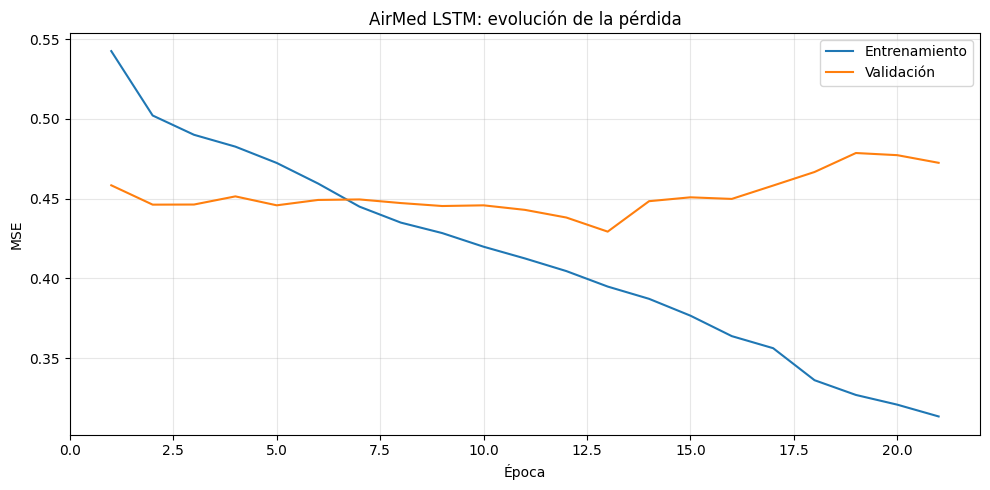

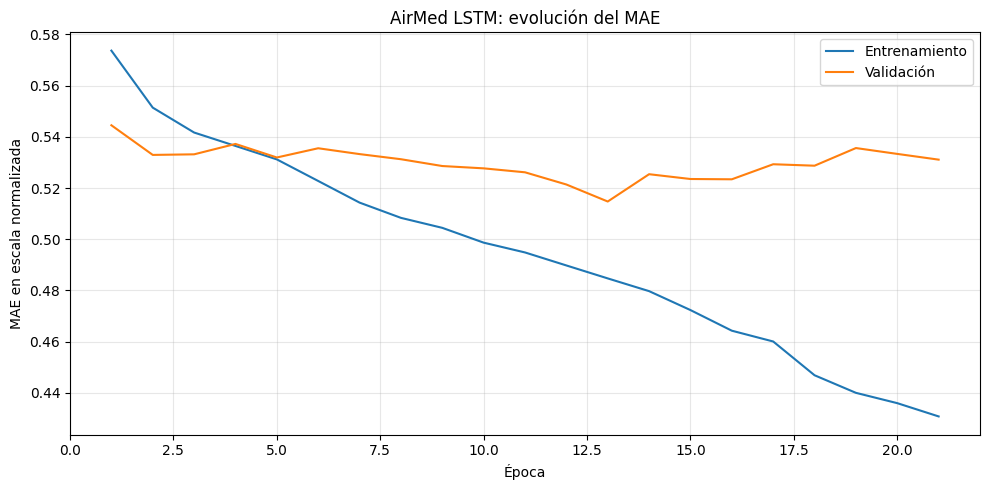

In [12]:
# ============================================================
# AIRMED
# PASO 6.4: CURVAS DE APRENDIZAJE
# ============================================================

import matplotlib.pyplot as plt

historial = historial_lstm.history

epocas = range(1, len(historial["loss"]) + 1)

# ------------------------------------------------------------
# Grafica 1: Error cuadratico medio
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epocas,
    historial["loss"],
    label="Entrenamiento"
)

plt.plot(
    epocas,
    historial["val_loss"],
    label="Validación"
)

plt.title("AirMed LSTM: evolución de la pérdida")
plt.xlabel("Época")
plt.ylabel("MSE")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Grafica 2: Error absoluto medio
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epocas,
    historial["mae"],
    label="Entrenamiento"
)

plt.plot(
    epocas,
    historial["val_mae"],
    label="Validación"
)

plt.title("AirMed LSTM: evolución del MAE")
plt.xlabel("Época")
plt.ylabel("MAE en escala normalizada")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

RESULTADOS INICIALES DE AIRMED LSTM
--------------------------------------------------
MAE de validación: 5.254 µg/m³
RMSE de validación: 6.652 µg/m³


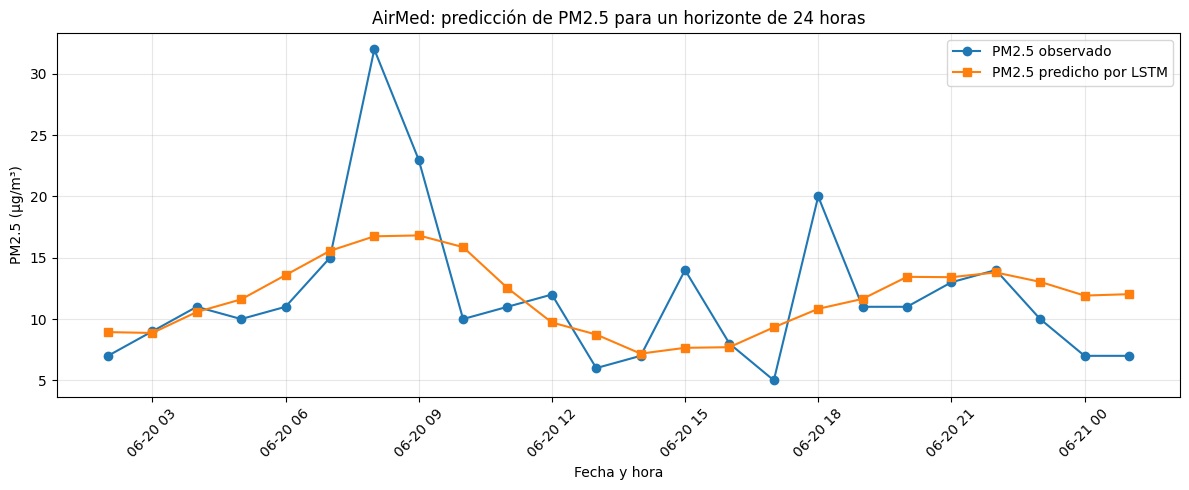

In [14]:
# ============================================================
# AIRMED
# PASO 6.5: EVALUACION INICIAL DEL MODELO LSTM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. Generar predicciones sobre validación
# ------------------------------------------------------------

predicciones_val_scaled = modelo_lstm.predict(
    X_val,
    verbose=0
)

# ------------------------------------------------------------
# 2. Convertir valores normalizados a unidades originales
# ------------------------------------------------------------

y_val_real = scaler.inverse_transform(
    y_val.reshape(-1, 1)
).reshape(y_val.shape)

predicciones_val = scaler.inverse_transform(
    predicciones_val_scaled.reshape(-1, 1)
).reshape(predicciones_val_scaled.shape)

# ------------------------------------------------------------
# 3. Calcular métricas
# ------------------------------------------------------------

mae_val = mean_absolute_error(
    y_val_real.ravel(),
    predicciones_val.ravel()
)

rmse_val = np.sqrt(
    mean_squared_error(
        y_val_real.ravel(),
        predicciones_val.ravel()
    )
)

print("RESULTADOS INICIALES DE AIRMED LSTM")
print("-" * 50)

print(f"MAE de validación: {mae_val:.3f} µg/m³")
print(f"RMSE de validación: {rmse_val:.3f} µg/m³")

# ------------------------------------------------------------
# 4. Mostrar predicción y valores reales para un horizonte
# ------------------------------------------------------------

muestra = 0

indice_inicio = indices_val[muestra]

fechas_prediccion = df_model["timestamp"].iloc[
    indice_inicio:indice_inicio + HORIZONTE
]

valores_reales = y_val_real[muestra]
valores_predichos = predicciones_val[muestra]

plt.figure(figsize=(12, 5))

plt.plot(
    fechas_prediccion,
    valores_reales,
    marker="o",
    label="PM2.5 observado"
)

plt.plot(
    fechas_prediccion,
    valores_predichos,
    marker="s",
    label="PM2.5 predicho por LSTM"
)

plt.title(
    "AirMed: predicción de PM2.5 para un horizonte de 24 horas"
)

plt.xlabel("Fecha y hora")
plt.ylabel("PM2.5 (µg/m³)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

AIRMED: COMPARACION DE MODELOS EN VALIDACION
-------------------------------------------------------


,Modelo,MAE (µg/m³),RMSE (µg/m³)
0,Persistencia,6.764,9.081
1,LSTM,5.254,6.652



MEJORA DE LA LSTM FRENTE A LA PERSISTENCIA
Mejora en MAE: 22.32%
Mejora en RMSE: 26.75%

La LSTM obtiene un MAE inferior al modelo de persistencia.


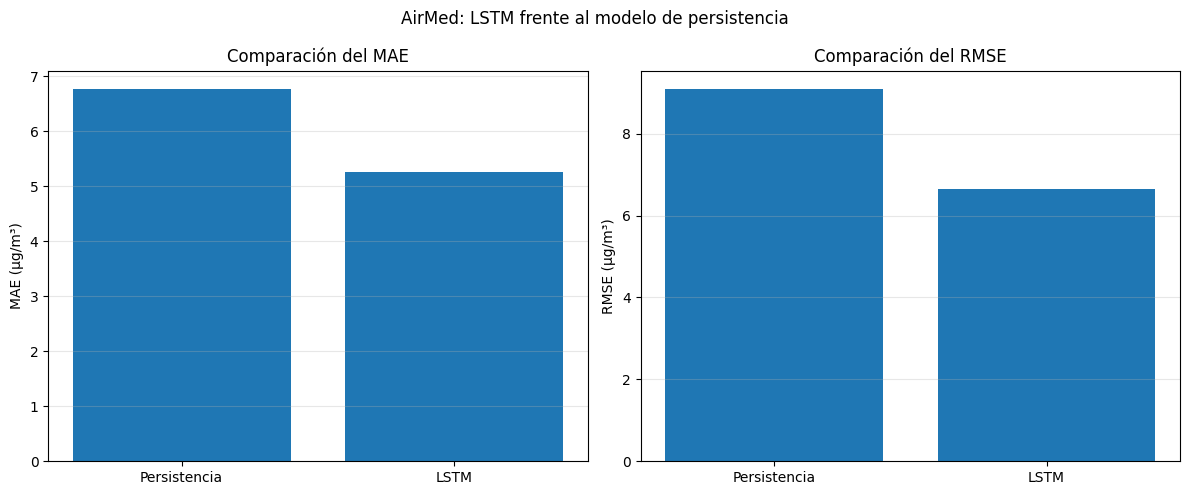

In [15]:
# ============================================================
# AIRMED
# PASO 6.6: COMPARACION CONTRA UN MODELO DE PERSISTENCIA
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. Obtener las predicciones de la LSTM
# ------------------------------------------------------------

pred_lstm_scaled = modelo_lstm.predict(
    X_val,
    verbose=0
)

# ------------------------------------------------------------
# 2. Convertir los valores a sus unidades originales
# ------------------------------------------------------------

y_val_real = scaler.inverse_transform(
    y_val.reshape(-1, 1)
).reshape(y_val.shape)

pred_lstm = scaler.inverse_transform(
    pred_lstm_scaled.reshape(-1, 1)
).reshape(pred_lstm_scaled.shape)

# ------------------------------------------------------------
# 3. Construir el modelo de persistencia
# ------------------------------------------------------------

# Tomar la ultima medicion de cada secuencia de entrada
ultima_medicion_scaled = X_val[:, -1, 0]

# Utilizar esa medicion para las siguientes 24 horas
pred_persistencia_scaled = np.repeat(
    ultima_medicion_scaled[:, np.newaxis],
    HORIZONTE,
    axis=1
)

# Transformar las predicciones a µg/m³
pred_persistencia = scaler.inverse_transform(
    pred_persistencia_scaled.reshape(-1, 1)
).reshape(pred_persistencia_scaled.shape)

# ------------------------------------------------------------
# 4. Calcular las metricas para ambos modelos
# ------------------------------------------------------------

resultados = []

for nombre, predicciones in [
    ("Persistencia", pred_persistencia),
    ("LSTM", pred_lstm)
]:

    mae = mean_absolute_error(
        y_val_real.ravel(),
        predicciones.ravel()
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val_real.ravel(),
            predicciones.ravel()
        )
    )

    resultados.append({
        "Modelo": nombre,
        "MAE (µg/m³)": mae,
        "RMSE (µg/m³)": rmse
    })

comparacion = pd.DataFrame(resultados)

print("AIRMED: COMPARACION DE MODELOS EN VALIDACION")
print("-" * 55)

display(
    comparacion.round(3)
)

# ------------------------------------------------------------
# 5. Calcular la mejora porcentual de la LSTM
# ------------------------------------------------------------

mae_baseline = comparacion.loc[
    comparacion["Modelo"] == "Persistencia",
    "MAE (µg/m³)"
].iloc[0]

mae_lstm = comparacion.loc[
    comparacion["Modelo"] == "LSTM",
    "MAE (µg/m³)"
].iloc[0]

rmse_baseline = comparacion.loc[
    comparacion["Modelo"] == "Persistencia",
    "RMSE (µg/m³)"
].iloc[0]

rmse_lstm = comparacion.loc[
    comparacion["Modelo"] == "LSTM",
    "RMSE (µg/m³)"
].iloc[0]

mejora_mae = (
    (mae_baseline - mae_lstm) / mae_baseline
) * 100

mejora_rmse = (
    (rmse_baseline - rmse_lstm) / rmse_baseline
) * 100

print("\nMEJORA DE LA LSTM FRENTE A LA PERSISTENCIA")
print(f"Mejora en MAE: {mejora_mae:.2f}%")
print(f"Mejora en RMSE: {mejora_rmse:.2f}%")

if mejora_mae > 0:
    print("\nLa LSTM obtiene un MAE inferior al modelo de persistencia.")
elif mejora_mae < 0:
    print("\nLa persistencia obtiene un MAE inferior al de la LSTM.")
else:
    print("\nAmbos modelos obtienen el mismo MAE.")

# ------------------------------------------------------------
# 6. Visualizar la comparacion
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

axes[0].bar(
    comparacion["Modelo"],
    comparacion["MAE (µg/m³)"]
)

axes[0].set_title("Comparación del MAE")
axes[0].set_ylabel("MAE (µg/m³)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    comparacion["Modelo"],
    comparacion["RMSE (µg/m³)"]
)

axes[1].set_title("Comparación del RMSE")
axes[1].set_ylabel("RMSE (µg/m³)")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle(
    "AirMed: LSTM frente al modelo de persistencia"
)

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# AIRMED
# PASO 7.3: CONSTRUCCION Y ENTRENAMIENTO DE LA RED GRU
# ============================================================

import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

# Fijar la semilla para facilitar la reproducibilidad
tf.keras.utils.set_random_seed(42)

# ------------------------------------------------------------
# 1. Construir la arquitectura GRU
# ------------------------------------------------------------

modelo_gru = Sequential([
    # Entrada: 168 horas historicas y una variable
    Input(shape=(LONGITUD_ENTRADA, 1)),

    # Capa recurrente GRU
    GRU(
        units=64,
        return_sequences=False
    ),

    # Regularizacion
    Dropout(0.20),

    # Capa densa intermedia
    Dense(
        units=32,
        activation="relu"
    ),

    # Salida: predicciones para las siguientes 24 horas
    Dense(
        units=HORIZONTE,
        activation="linear"
    )
])

# ------------------------------------------------------------
# 2. Compilar el modelo
# ------------------------------------------------------------

modelo_gru.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Mostrar la arquitectura
print("ARQUITECTURA DEL MODELO AIRMED GRU")
print("-" * 50)

modelo_gru.summary()

# ------------------------------------------------------------
# 3. Configurar los callbacks
# ------------------------------------------------------------

early_stopping_gru = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_gru = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=0.00001,
    verbose=1
)

# ------------------------------------------------------------
# 4. Entrenar el modelo
# ------------------------------------------------------------

print("\nINICIANDO EL ENTRENAMIENTO DE AIRMED GRU")

historial_gru = modelo_gru.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[
        early_stopping_gru,
        reduce_lr_gru
    ],
    shuffle=True,
    verbose=1
)

print("\nENTRENAMIENTO GRU FINALIZADO")
print("-" * 45)

print(
    "Épocas ejecutadas:",
    len(historial_gru.history["loss"])
)

print(
    "Mejor pérdida de validación:",
    round(
        min(historial_gru.history["val_loss"]),
        5
    )
)

ARQUITECTURA DEL MODELO AIRMED GRU
--------------------------------------------------


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,736 (61.47 KB)

 Trainable params: 15,736 (61.47 KB)

 Non-trainable params: 0 (0.00 B)


INICIANDO EL ENTRENAMIENTO DE AIRMED GRU
Epoch 1/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 13s 78ms/step - loss: 0.5441 - mae: 0.5754 - val_loss: 0.4606 - val_mae: 0.5435 - learning_rate: 0.0010
Epoch 2/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 8s 87ms/step - loss: 0.4998 - mae: 0.5493 - val_loss: 0.4432 - val_mae: 0.5297 - learning_rate: 0.0010
Epoch 3/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - loss: 0.4899 - mae: 0.5423 - val_loss: 0.4403 - val_mae: 0.5265 - learning_rate: 0.0010
Epoch 4/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - loss: 0.4850 - mae: 0.5381 - val_loss: 0.4387 - val_mae: 0.5246 - learning_rate: 0.0010
Epoch 5/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 9s 96ms/step - loss: 0.4748 - mae: 0.5321 - val_loss: 0.4347 - val_mae: 0.5220 - learning_rate: 0.0010
Epoch 6/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 12s 111ms/step - loss: 0.4590 - mae: 0.5243 - val_loss: 0.4260 - val_mae: 0.5196 - learning_rate: 0.0010
Epoch 7/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 11s 116ms/step - loss: 0.4487 - mae: 0.5179 - val_loss: 0.4232 - val_ma

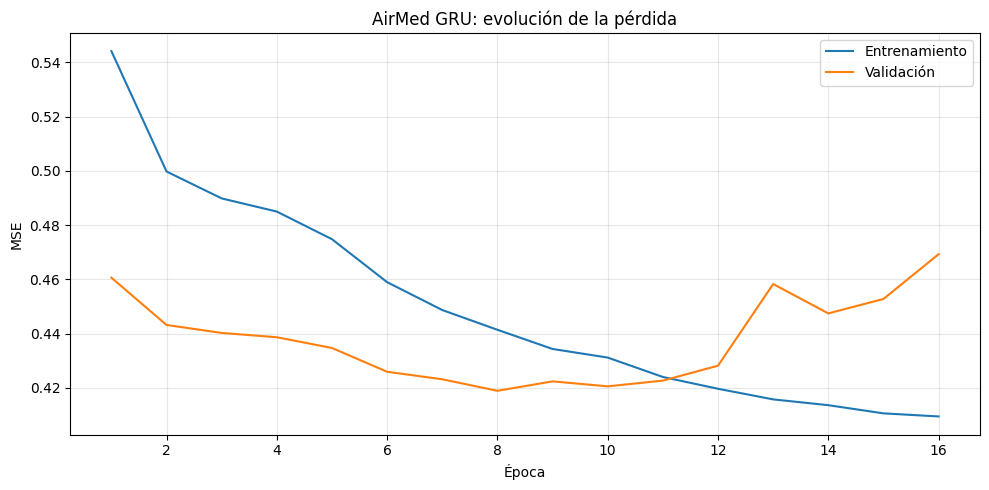

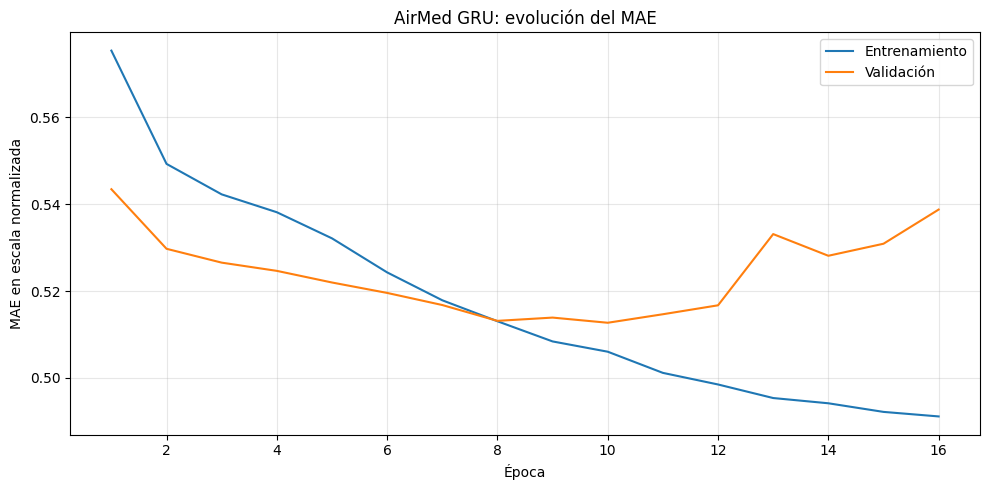

In [17]:
# ============================================================
# AIRMED
# PASO 7.4: CURVAS DE APRENDIZAJE DE LA GRU
# ============================================================

historial = historial_gru.history

epocas = range(
    1,
    len(historial["loss"]) + 1
)

# ------------------------------------------------------------
# 1. Evolucion de la perdida
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epocas,
    historial["loss"],
    label="Entrenamiento"
)

plt.plot(
    epocas,
    historial["val_loss"],
    label="Validación"
)

plt.title("AirMed GRU: evolución de la pérdida")
plt.xlabel("Época")
plt.ylabel("MSE")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. Evolucion del MAE
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epocas,
    historial["mae"],
    label="Entrenamiento"
)

plt.plot(
    epocas,
    historial["val_mae"],
    label="Validación"
)

plt.title("AirMed GRU: evolución del MAE")
plt.xlabel("Época")
plt.ylabel("MAE en escala normalizada")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# AIRMED
# PASO 7.5: COMPARACION ENTRE PERSISTENCIA, LSTM Y GRU
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# 1. Recuperar los valores reales de validacion
# ------------------------------------------------------------

y_val_real = scaler.inverse_transform(
    y_val.reshape(-1, 1)
).reshape(y_val.shape)

# ------------------------------------------------------------
# 2. Obtener las predicciones de la LSTM
# ------------------------------------------------------------

pred_lstm_scaled = modelo_lstm.predict(
    X_val,
    verbose=0
)

pred_lstm = scaler.inverse_transform(
    pred_lstm_scaled.reshape(-1, 1)
).reshape(pred_lstm_scaled.shape)

# ------------------------------------------------------------
# 3. Obtener las predicciones de la GRU
# ------------------------------------------------------------

pred_gru_scaled = modelo_gru.predict(
    X_val,
    verbose=0
)

pred_gru = scaler.inverse_transform(
    pred_gru_scaled.reshape(-1, 1)
).reshape(pred_gru_scaled.shape)

# ------------------------------------------------------------
# 4. Construir las predicciones de persistencia
# ------------------------------------------------------------

ultima_medicion_scaled = X_val[:, -1, 0]

pred_persistencia_scaled = np.repeat(
    ultima_medicion_scaled[:, np.newaxis],
    HORIZONTE,
    axis=1
)

pred_persistencia = scaler.inverse_transform(
    pred_persistencia_scaled.reshape(-1, 1)
).reshape(pred_persistencia_scaled.shape)

# ------------------------------------------------------------
# 5. Calcular metricas para los tres modelos
# ------------------------------------------------------------

predicciones_modelos = {
    "Persistencia": pred_persistencia,
    "LSTM": pred_lstm,
    "GRU": pred_gru
}

resultados = []

for nombre, predicciones in predicciones_modelos.items():

    mae = mean_absolute_error(
        y_val_real.ravel(),
        predicciones.ravel()
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val_real.ravel(),
            predicciones.ravel()
        )
    )

    resultados.append({
        "Modelo": nombre,
        "MAE (µg/m³)": mae,
        "RMSE (µg/m³)": rmse
    })

comparacion_modelos = pd.DataFrame(
    resultados
)

print("AIRMED: COMPARACION DE MODELOS EN VALIDACION")
print("-" * 60)

display(
    comparacion_modelos.round(3)
)

# ------------------------------------------------------------
# 6. Calcular la mejora frente a persistencia
# ------------------------------------------------------------

mae_baseline = comparacion_modelos.loc[
    comparacion_modelos["Modelo"] == "Persistencia",
    "MAE (µg/m³)"
].iloc[0]

rmse_baseline = comparacion_modelos.loc[
    comparacion_modelos["Modelo"] == "Persistencia",
    "RMSE (µg/m³)"
].iloc[0]

print("\nMEJORA DE CADA RED FRENTE A PERSISTENCIA")

for nombre in ["LSTM", "GRU"]:

    fila = comparacion_modelos[
        comparacion_modelos["Modelo"] == nombre
    ].iloc[0]

    mejora_mae = (
        (mae_baseline - fila["MAE (µg/m³)"])
        / mae_baseline
    ) * 100

    mejora_rmse = (
        (rmse_baseline - fila["RMSE (µg/m³)"])
        / rmse_baseline
    ) * 100

    print(f"\n{nombre}")
    print(f"Mejora en MAE: {mejora_mae:.2f}%")
    print(f"Mejora en RMSE: {mejora_rmse:.2f}%")

AIRMED: COMPARACION DE MODELOS EN VALIDACION
------------------------------------------------------------


,Modelo,MAE (µg/m³),RMSE (µg/m³)
0,Persistencia,6.764,9.081
1,LSTM,5.254,6.652
2,GRU,5.131,6.473



MEJORA DE CADA RED FRENTE A PERSISTENCIA

LSTM
Mejora en MAE: 22.32%
Mejora en RMSE: 26.75%

GRU
Mejora en MAE: 24.14%
Mejora en RMSE: 28.72%


In [19]:
# ============================================================
# AIRMED
# PASO 8: GUARDAR EL MODELO Y LOS RESULTADOS
# ============================================================

from pathlib import Path
import json
import joblib

# Directorio principal del proyecto en Google Drive
BASE_DIR = Path("/content/drive/MyDrive/AirMed")

# Crear las carpetas necesarias
MODELS_DIR = BASE_DIR / "models"
METRICS_DIR = BASE_DIR / "results" / "metrics"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Guardar el modelo GRU
# ------------------------------------------------------------

ruta_modelo = MODELS_DIR / "airmed_gru_univariate.keras"

modelo_gru.save(ruta_modelo)

# ------------------------------------------------------------
# 2. Guardar el escalador
# ------------------------------------------------------------

ruta_scaler = MODELS_DIR / "robust_scaler_pm25.joblib"

joblib.dump(scaler, ruta_scaler)

# ------------------------------------------------------------
# 3. Guardar las metricas de validacion
# ------------------------------------------------------------

ruta_metricas = (
    METRICS_DIR / "comparacion_modelos_validacion.csv"
)

comparacion_modelos.to_csv(
    ruta_metricas,
    index=False
)

# ------------------------------------------------------------
# 4. Guardar la configuracion del experimento
# ------------------------------------------------------------

configuracion = {
    "proyecto": "AirMed",
    "estacion": "MED-PBLQ",
    "variable_objetivo": "pm25_ug_m3",
    "frecuencia": "horaria",
    "longitud_entrada_horas": LONGITUD_ENTRADA,
    "horizonte_prediccion_horas": HORIZONTE,
    "arquitectura_seleccionada": "GRU",
    "unidades_gru": 64,
    "dropout": 0.20,
    "unidades_dense": 32,
    "batch_size": 32,
    "epocas_maximas": 50,
    "semilla": 42,
    "escalador": "RobustScaler",
    "criterio_seleccion": "MAE de validacion"
}

ruta_configuracion = (
    MODELS_DIR / "configuracion_experimento.json"
)

with open(
    ruta_configuracion,
    "w",
    encoding="utf-8"
) as archivo:

    json.dump(
        configuracion,
        archivo,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# 5. Confirmar que los archivos existen
# ------------------------------------------------------------

print("ARTEFACTOS GUARDADOS CORRECTAMENTE")
print("-" * 50)

for ruta in [
    ruta_modelo,
    ruta_scaler,
    ruta_metricas,
    ruta_configuracion
]:

    print(f"{ruta.name}: {'OK' if ruta.exists() else 'ERROR'}")
    print(f"Ubicacion: {ruta}")
    print()

ARTEFACTOS GUARDADOS CORRECTAMENTE
--------------------------------------------------
airmed_gru_univariate.keras: OK
Ubicacion: /content/drive/MyDrive/AirMed/models/airmed_gru_univariate.keras

robust_scaler_pm25.joblib: OK
Ubicacion: /content/drive/MyDrive/AirMed/models/robust_scaler_pm25.joblib

comparacion_modelos_validacion.csv: OK
Ubicacion: /content/drive/MyDrive/AirMed/results/metrics/comparacion_modelos_validacion.csv

configuracion_experimento.json: OK
Ubicacion: /content/drive/MyDrive/AirMed/models/configuracion_experimento.json



AIRMED: RESULTADOS FINALES EN EL CONJUNTO DE PRUEBA
-----------------------------------------------------------------


,Modelo,MAE (µg/m³),RMSE (µg/m³)
0,Persistencia,6.935,8.995
1,GRU,5.008,6.292



MEJORA DE LA GRU FRENTE A PERSISTENCIA
MAE: 27.79%
RMSE: 30.05%


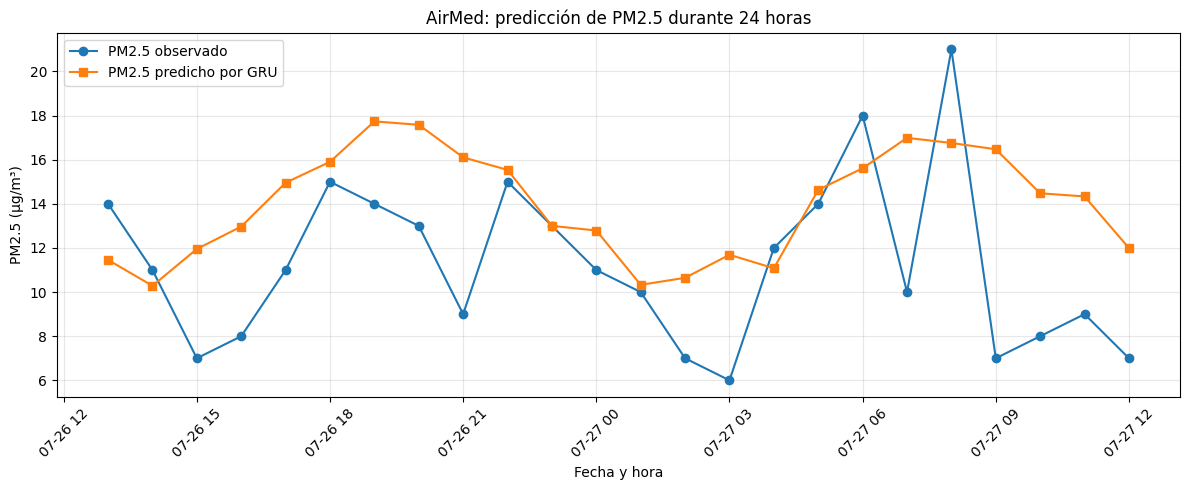


Metricas de prueba guardadas en:
/content/drive/MyDrive/AirMed/results/metrics/metricas_finales_prueba.csv


In [20]:
# ============================================================
# AIRMED
# PASO 9: EVALUACION FINAL EN EL CONJUNTO DE PRUEBA
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. Generar las predicciones de la GRU
# ------------------------------------------------------------

pred_test_scaled = modelo_gru.predict(
    X_test,
    verbose=0
)

# ------------------------------------------------------------
# 2. Convertir los resultados a unidades originales
# ------------------------------------------------------------

y_test_real = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).reshape(y_test.shape)

pred_gru_test = scaler.inverse_transform(
    pred_test_scaled.reshape(-1, 1)
).reshape(pred_test_scaled.shape)

# ------------------------------------------------------------
# 3. Construir el modelo de persistencia
# ------------------------------------------------------------

# Ultima medicion historica de cada secuencia
ultima_medicion_test = X_test[:, -1, 0]

# Repetirla para las siguientes 24 horas
pred_persistencia_scaled = np.repeat(
    ultima_medicion_test[:, np.newaxis],
    HORIZONTE,
    axis=1
)

# Recuperar las unidades originales
pred_persistencia_test = scaler.inverse_transform(
    pred_persistencia_scaled.reshape(-1, 1)
).reshape(pred_persistencia_scaled.shape)

# ------------------------------------------------------------
# 4. Calcular las metricas
# ------------------------------------------------------------

resultados_test = []

for nombre, predicciones in [
    ("Persistencia", pred_persistencia_test),
    ("GRU", pred_gru_test)
]:

    mae = mean_absolute_error(
        y_test_real.ravel(),
        predicciones.ravel()
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_real.ravel(),
            predicciones.ravel()
        )
    )

    resultados_test.append({
        "Modelo": nombre,
        "MAE (µg/m³)": mae,
        "RMSE (µg/m³)": rmse
    })

metricas_test = pd.DataFrame(resultados_test)

print("AIRMED: RESULTADOS FINALES EN EL CONJUNTO DE PRUEBA")
print("-" * 65)

display(metricas_test.round(3))

# ------------------------------------------------------------
# 5. Calcular la mejora de la GRU
# ------------------------------------------------------------

mae_base = metricas_test.loc[
    metricas_test["Modelo"] == "Persistencia",
    "MAE (µg/m³)"
].iloc[0]

mae_gru = metricas_test.loc[
    metricas_test["Modelo"] == "GRU",
    "MAE (µg/m³)"
].iloc[0]

rmse_base = metricas_test.loc[
    metricas_test["Modelo"] == "Persistencia",
    "RMSE (µg/m³)"
].iloc[0]

rmse_gru = metricas_test.loc[
    metricas_test["Modelo"] == "GRU",
    "RMSE (µg/m³)"
].iloc[0]

mejora_mae_test = (
    (mae_base - mae_gru) / mae_base
) * 100

mejora_rmse_test = (
    (rmse_base - rmse_gru) / rmse_base
) * 100

print("\nMEJORA DE LA GRU FRENTE A PERSISTENCIA")
print(f"MAE: {mejora_mae_test:.2f}%")
print(f"RMSE: {mejora_rmse_test:.2f}%")

# ------------------------------------------------------------
# 6. Graficar una prediccion de 24 horas
# ------------------------------------------------------------

muestra = 0

indice_inicio = indices_test[muestra]

fechas_test = df_model["timestamp"].iloc[
    indice_inicio:indice_inicio + HORIZONTE
]

plt.figure(figsize=(12, 5))

plt.plot(
    fechas_test,
    y_test_real[muestra],
    marker="o",
    label="PM2.5 observado"
)

plt.plot(
    fechas_test,
    pred_gru_test[muestra],
    marker="s",
    label="PM2.5 predicho por GRU"
)

plt.title(
    "AirMed: predicción de PM2.5 durante 24 horas"
)

plt.xlabel("Fecha y hora")
plt.ylabel("PM2.5 (µg/m³)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Guardar las metricas finales
# ------------------------------------------------------------

ruta_metricas_test = (
    METRICS_DIR / "metricas_finales_prueba.csv"
)

metricas_test.to_csv(
    ruta_metricas_test,
    index=False
)

print("\nMetricas de prueba guardadas en:")
print(ruta_metricas_test)

In [21]:
# ============================================================
# AIRMED
# PASO 10.2: CONSOLIDAR LOS RESULTADOS DEL EXPERIMENTO
# ============================================================

import pandas as pd
from pathlib import Path

# Resultados de validación
resultados_validacion = comparacion_modelos.copy()
resultados_validacion["Conjunto"] = "Validación"

# Resultados de prueba
resultados_prueba = metricas_test.copy()
resultados_prueba["Conjunto"] = "Prueba"

# Unificar las tablas
resultados_finales = pd.concat(
    [
        resultados_validacion,
        resultados_prueba
    ],
    ignore_index=True
)

# Organizar las columnas
resultados_finales = resultados_finales[
    [
        "Conjunto",
        "Modelo",
        "MAE (µg/m³)",
        "RMSE (µg/m³)"
    ]
]

# Mostrar la tabla
print("AIRMED: RESULTADOS CONSOLIDADOS")
display(resultados_finales.round(3))

# Guardar los resultados en Google Drive
ruta_resultados = Path(
    "/content/drive/MyDrive/AirMed/results/metrics"
)

ruta_resultados.mkdir(
    parents=True,
    exist_ok=True
)

archivo_resultados = (
    ruta_resultados / "airmed_resultados_consolidados.csv"
)

resultados_finales.to_csv(
    archivo_resultados,
    index=False
)

print("\nResultados guardados en:")
print(archivo_resultados)

AIRMED: RESULTADOS CONSOLIDADOS


,Conjunto,Modelo,MAE (µg/m³),RMSE (µg/m³)
0,Validación,Persistencia,6.764,9.081
1,Validación,LSTM,5.254,6.652
2,Validación,GRU,5.131,6.473
3,Prueba,Persistencia,6.935,8.995
4,Prueba,GRU,5.008,6.292



Resultados guardados en:
/content/drive/MyDrive/AirMed/results/metrics/airmed_resultados_consolidados.csv
